In [2]:
import torch
import torch.optim as optim
import numpy as np
from scipy.optimize import linear_sum_assignment
# import plotly.graph_objects as go
import matplotlib.pyplot as plt

In [38]:

torch.manual_seed(45)


random_xy = torch.rand((50, 2), dtype=torch.float32) * 250.0
random_z = torch.zeros((50, 1), dtype=torch.float32)

strings = torch.cat([random_xy, random_z], dim=1)
N_strings = strings.shape[0]

print(strings)

tensor([[ 46.7369, 240.3321,   0.0000],
        [170.8622, 224.6990,   0.0000],
        [ 12.6271, 138.8640,   0.0000],
        [196.5322,  14.1557,   0.0000],
        [196.0473,  36.9959,   0.0000],
        [  9.7102,  25.9341,   0.0000],
        [105.4079,  59.3348,   0.0000],
        [202.7647, 133.5038,   0.0000],
        [170.8459, 163.2059,   0.0000],
        [153.0677, 245.8376,   0.0000],
        [ 45.6512,  30.9793,   0.0000],
        [106.5548, 242.9182,   0.0000],
        [156.1876, 195.5470,   0.0000],
        [102.4479,  86.7655,   0.0000],
        [ 70.8468, 188.0260,   0.0000],
        [ 90.7012, 156.0838,   0.0000],
        [214.2124, 197.8020,   0.0000],
        [ 76.3520,   9.4034,   0.0000],
        [193.9770,  78.9648,   0.0000],
        [ 39.9899, 145.9440,   0.0000],
        [120.7796,  28.0103,   0.0000],
        [197.4973,  45.3217,   0.0000],
        [ 25.1067,  41.3743,   0.0000],
        [127.3476, 144.8142,   0.0000],
        [ 36.5221, 165.6529,   0.0000],


In [39]:
C_cable=200
C_cjb=150e3
cjb_capacity=8
max_cjbs=10

In [40]:
cjbs = torch.tensor([
    [1, 1, 0], [20, 20, 0], [50, 50, 0],
    [70, 70, 0], [100, 100, 0], [130, 130, 0],
    [160, 160, 0], [190, 190, 0], [220, 220, 0], [210, 210, 0
]], dtype=torch.float32, requires_grad=True)

In [26]:
#optimizer=optim.Adam([cjbs], lr=1)

In [27]:
#def hungarian_algorithm(strings, cjbs):
 # dists=torch.cdist(strings, cjbs).detach().numpy()
 # expanded_dists=np.repeat(dists, cjb_capacity, axis=1)
 # cost_matrix=expanded_dists*C_cable
 # string_indices, slot_indices=linear_sum_assignment(cost_matrix)
 # cjb_assignments=slot_indices//cjb_capacity
  #print(string_indices, slot_indices)
 # return cjb_assignments


In [41]:
def soft_assignment(strings, cjbs, beta=0.5):

    dists = torch.cdist(strings, cjbs)

    assignment_weights = torch.softmax(-beta * dists, dim=1)

    return assignment_weights

In [42]:
assignment_logits = torch.zeros((strings.shape[0], cjbs.shape[0]), dtype=torch.float32, requires_grad=True)
cjbs = torch.tensor([
    [1, 1, 0], [20, 20, 0], [50, 50, 0],
    [70, 70, 0], [100, 100, 0], [130, 130, 0],
    [160, 160, 0], [190, 190, 0], [220, 220, 0], [210, 210, 0
]], dtype=torch.float32, requires_grad=True)


optimizer_cjb = optim.Adam([cjbs], lr=5)
optimizer_cable = optim.Adam([assignment_logits], lr=1)

history_cjbs = [cjbs.detach().clone().numpy()]
history_weights = []

C_capacity_penalty = 500000
C_cable_penalty = 50000

for i in range(50000):
    optimizer_cjb.zero_grad()
    optimizer_cable.zero_grad()

    dists = torch.cdist(strings, cjbs)

    weights = torch.softmax(assignment_logits, dim=1)

    expected_cable_lengths = torch.sum(weights * dists, dim=1)
    cable_cost = C_cable * torch.sum(expected_cable_lengths)

    cjb_usage = torch.sum(weights, dim=0)
    soft_active_cjbs = torch.sum(torch.sigmoid((cjb_usage-0.9) * 3.0))
    number_of_cjb_cost = C_cjb * soft_active_cjbs

    excess_usage = torch.nn.functional.softplus(cjb_usage - cjb_capacity, beta=2)
    capacity_penalty_cost = C_capacity_penalty * torch.sum(excess_usage ** 2)

    loss = cable_cost + number_of_cjb_cost + capacity_penalty_cost

    loss.backward()
    optimizer_cjb.step()
    optimizer_cable.step()
    max_soft_usage = torch.max(cjb_usage).item()

    if (i + 1) % 500 == 0:
        print(f"Epoch {i + 1} | Loss: {loss.item():.2f} | Soft Active CJBs: {soft_active_cjbs.item():.2f}")

print(f"Max Soft Usage: {max_soft_usage}")
history_cjbs.append(cjbs.detach().clone().numpy())
history_weights.append(weights.detach().clone().numpy())

Epoch 500 | Loss: 1601246.00 | Soft Active CJBs: 7.19
Epoch 1000 | Loss: 1570237.50 | Soft Active CJBs: 7.19
Epoch 1500 | Loss: 1566065.75 | Soft Active CJBs: 7.19
Epoch 2000 | Loss: 1565917.88 | Soft Active CJBs: 7.19
Epoch 2500 | Loss: 1565954.62 | Soft Active CJBs: 7.19
Epoch 3000 | Loss: 1565074.25 | Soft Active CJBs: 7.19
Epoch 3500 | Loss: 1565351.88 | Soft Active CJBs: 7.19
Epoch 4000 | Loss: 1562396.88 | Soft Active CJBs: 7.19
Epoch 4500 | Loss: 1562359.50 | Soft Active CJBs: 7.19
Epoch 5000 | Loss: 1541042.12 | Soft Active CJBs: 7.19
Epoch 5500 | Loss: 1541052.50 | Soft Active CJBs: 7.19
Epoch 6000 | Loss: 1541044.62 | Soft Active CJBs: 7.19
Epoch 6500 | Loss: 1541043.00 | Soft Active CJBs: 7.19
Epoch 7000 | Loss: 1541079.75 | Soft Active CJBs: 7.19
Epoch 7500 | Loss: 1541016.12 | Soft Active CJBs: 7.19
Epoch 8000 | Loss: 1540940.00 | Soft Active CJBs: 7.19
Epoch 8500 | Loss: 1540797.38 | Soft Active CJBs: 7.19
Epoch 9000 | Loss: 1540567.00 | Soft Active CJBs: 7.19
Epoch 9500 

In [30]:
#hungarian_algorithm(strings, cjbs)

In [31]:
#for i in range(1000):
 # optimizer.zero_grad()
 # cjb_indices=hungarian_algorithm(strings, cjbs)
 # assigned_cjbs=cjbs[cjb_indices]
 # cable_lengths=torch.norm(strings-assigned_cjbs, dim=1)
 # cable_cost=C_cable*torch.sum(cable_lengths)

 # unique_active_cjbs=torch.unique(torch.tensor(cjb_indices))
 # number_of_cjb_cost=C_cjb*len(unique_active_cjbs)
 # loss=cable_cost + number_of_cjb_cost
 # loss.backward()
 # optimizer.step()


 # if (i+1)%100==0:
  #  print(f"Epoch {i + 1}")
  #  print(f"  Loss: {loss.item():.5f}")
  #  print(f"  Cable Length: {cable_lengths.sum().item():.1f}m")
  #  print(f"  Active CJBs: {len(unique_active_cjbs)}")
    #print(f"  New CJB Positions:\n{cjbs.detach().numpy()}")


In [32]:
#unique_active=np.unique(hungarian_algorithm(strings,cjbs))
#for i in range (max_cjbs):
 # status = "active" if i in unique_active else "off"
 # n_cables=np.sum(hungarian_algorithm(strings, cjbs) == i)
 # pos = cjbs[i].detach().numpy().round(1)

In [33]:
#import plotly.graph_objects as go

#strings_np=strings.detach().numpy()
#cjbs_np=cjbs.detach().numpy()
#fig=go.Figure()
#fig.add_trace(go.Scatter(
 #   x=strings_np[:, 0], y=strings_np[:, 1], mode="markers", marker=dict(size=5, color="red"), name=f"Strings ({N_strings})"))
#active_cjbs_np=cjbs_np[unique_active]
#fig.add_trace(go.Scatter(
 #   x=active_cjbs_np[:, 0], y=active_cjbs_np[:, 1],
 #  mode='markers',
 #  marker=dict(size=10, color='gold', symbol='diamond', line=dict(color='black', width=2)),
 #  name=f'Active CJBs ({len(unique_active)})'))
#cable_x, cable_y = [], []
#for s_idx, cjb_idx in enumerate(hungarian_algorithm(strings, cjbs)):
 #   s_pos = strings_np[s_idx]
  #  c_pos = cjbs_np[cjb_idx]
   # cable_x.extend([s_pos[0], c_pos[0], None])
    #cable_y.extend([s_pos[1], c_pos[1], None])
#fig.add_trace(go.Scatter(
 #   x=cable_x, y=cable_y,
  #  mode='lines',
   # line=dict(color='gray', width=1.5),
    #opacity=0.6,
    #name='Discrete Cable Assignments'))
#fig.update_layout(
 #   title=f"Hungarian Algorithm + PyTorch Optimization<br>Active CJBs: {len(unique_active)}/{max_cjbs} | Total Cost: ${loss.item():,.2f}",
  #  xaxis_title='X (meters)', yaxis_title='Y (meters)',
   # margin=dict(l=0, r=0, b=0, t=50))
#fig.show()


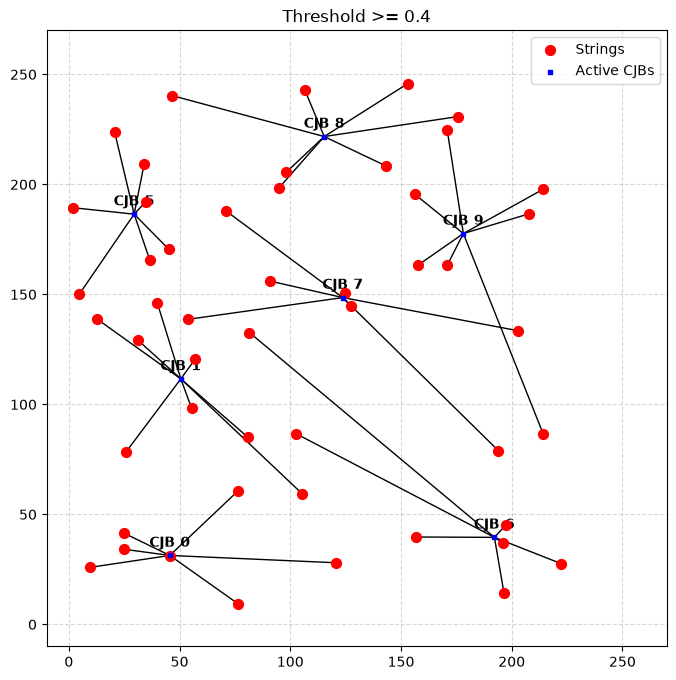

In [43]:
strings_np = strings.detach().cpu().numpy()
end_cjbs = history_cjbs[-1]

threshold = 0.4
final_weights = history_weights[-1]
cjb_usage_final = final_weights.sum(axis=0)

active_cjb_mask = cjb_usage_final >= threshold
active_cjb_indices = np.where(active_cjb_mask)[0]

hard_assignments = []
for s_idx in range(N_strings):
    best_cjb = np.argmax(final_weights[s_idx])
    if best_cjb in active_cjb_indices:
        hard_assignments.append(best_cjb)
    else:
        active_weights = final_weights[s_idx] * active_cjb_mask
        if np.sum(active_weights) > 0:
            hard_assignments.append(np.argmax(active_weights))
        else:
            hard_assignments.append(best_cjb)

hard_assignments = np.array(hard_assignments)


plt.figure(figsize=(8, 8))

for s_idx, cjb_idx in enumerate(hard_assignments):
    s_pos = strings_np[s_idx]
    c_pos = end_cjbs[cjb_idx]
    plt.plot([s_pos[0], c_pos[0]], [s_pos[1], c_pos[1]], color='black', linestyle='-', linewidth=1)

plt.scatter(strings_np[:, 0], strings_np[:, 1], color='red', s=50, label='Strings', zorder=5)

plt.scatter(end_cjbs[active_cjb_indices, 0], end_cjbs[active_cjb_indices, 1],
            color='blue', marker='s', s=10, label='Active CJBs', zorder=6)

for idx in active_cjb_indices:
    plt.text(end_cjbs[idx, 0], end_cjbs[idx, 1] + 4, f"CJB {idx}",
             fontsize=10, fontweight='bold', ha='center')

plt.title(f"Threshold >= {threshold}")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-10, 270)
plt.ylim(-10, 270)
plt.show()

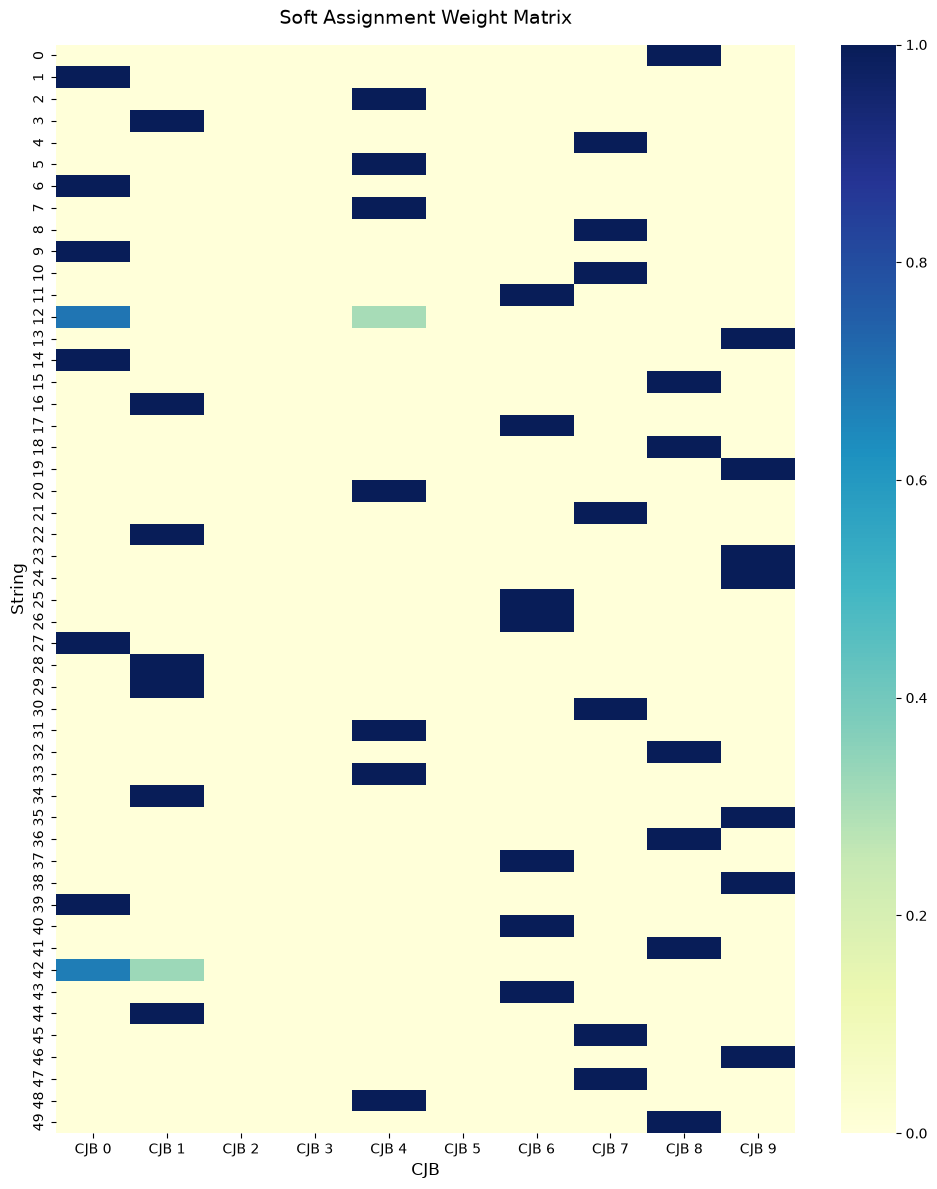

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 12))
sns.heatmap(final_weights, annot=False, cmap="YlGnBu", xticklabels=[f"CJB {i}" for i in range(max_cjbs)], yticklabels=[f"{i}" for i in range(N_strings)])

plt.title("Soft Assignment Weight Matrix", fontsize=14, pad=15)
plt.xlabel("CJB", fontsize=12)
plt.ylabel("String", fontsize=12)
plt.tight_layout()
plt.show()

In [36]:
total_length = 0.0
for s_idx, cjb_idx in enumerate(hard_assignments):
    s_pos = strings_np[s_idx]
    c_pos = end_cjbs[cjb_idx]

    dist = np.linalg.norm(s_pos - c_pos)
    total_length += dist

avg_length = total_length / N_strings
print(f"total length: {total_length:.2f} Meter")
print(f"average length: {avg_length:.2f} Meter")

total length: 1791.43 Meter
average length: 35.83 Meter
